# 01 · Exploring Canadian mortality, 1980–2024

**Data:** Statistics Canada, Table 13-10-0837-01 (complete life tables, Canada, single years of age 0–110+).
**Main variable:** `qx`, the probability that someone aged *x* dies before their next birthday.

Questions for this notebook:
1. Does our life-table code reproduce StatCan's published life expectancy? (a correctness check before any modelling)
2. What does the age pattern of mortality look like, and how has it moved?
3. How fast has mortality improved at different ages? (This is the key input for insurance pricing.)
4. How big was the COVID-19 shock (2020–2022) compared with the long-run trend?

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from src.data import load_qx, load_official_ex, qx_matrix
from src.lifetable import e0, life_expectancy

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#999999", "axes.labelcolor": "#333333",
    "xtick.color": "#666666", "ytick.color": "#666666", "lines.linewidth": 2,
})
COLORS = {"male": "#257de0", "female": "#f47230"}
FIG_DIR = "../reports/figures"

df = load_qx()
official = load_official_ex()
q = {s: qx_matrix(df, s) for s in ["male", "female"]}
df.head()

,year,sex,age,qx
0,1980,male,0,0.01171
1,1980,male,1,0.00084
2,1980,male,2,0.00072
3,1980,male,3,0.00062
4,1980,male,4,0.00054


## 1. Check: does our life table match StatCan?

Before modelling, I want to be sure the life-table code (`src/lifetable.py`) is correct. I rebuild period life expectancy at birth (e0) from `qx` and compare it with the figure StatCan publishes.

In [2]:
check = []
for s in ["male", "female"]:
    off = official.query("sex == @s and age == 0").set_index("year")["ex"]
    ours = pd.Series({y: e0(q[s][y].to_numpy()) for y in q[s].columns})
    check.append(pd.DataFrame({"sex": s, "ours": ours.round(2), "statcan": off, "diff": (ours - off).round(3)}))
check = pd.concat(check)
print("Largest absolute difference (years):", check["diff"].abs().max())
check.loc[[1980, 2000, 2019, 2021, 2024]].sort_index()

Largest absolute difference (years): 0.007


,sex,ours,statcan,diff
1980,male,71.58,71.59,-0.006
1980,female,78.79,78.79,0.004
2000,male,76.64,76.64,-0.004
2000,female,81.82,81.82,-0.001
2019,male,80.10,80.10,0.003
2019,female,84.32,84.32,-0.001
2021,male,79.10,79.11,-0.005
2021,female,83.91,83.91,-0.002
2024,male,80.03,80.03,0.003
2024,female,84.29,84.29,-0.003


The two agree to within 0.01 years in every year, for both sexes, so the life-table code can be trusted for later steps (forecast evaluation, insurance pricing).

## 2. Life expectancy at birth

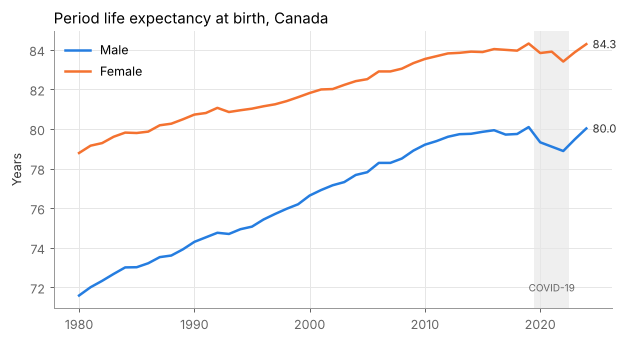

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for s in ["male", "female"]:
    e = check.query("sex == @s")["statcan"]
    ax.plot(e.index, e.values, color=COLORS[s], label=s.capitalize())
    ax.annotate(f"{e.iloc[-1]:.1f}", (e.index[-1], e.iloc[-1]), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=9, color="#333333")
ax.axvspan(2019.5, 2022.5, color="#999999", alpha=0.15, lw=0)
ax.text(2021, 71.8, "COVID-19", ha="center", fontsize=8, color="#666666")
ax.set_title("Period life expectancy at birth, Canada", loc="left")
ax.set_ylabel("Years")
ax.legend(frameon=False, loc="upper left")
fig.savefig(f"{FIG_DIR}/e0_trend.png", bbox_inches="tight", dpi=150)

In [4]:
e = check.pivot(columns="sex", values="statcan")
gap = (e["female"] - e["male"]).round(2)
print(f"Gain 1980→2019: male +{e.loc[2019,'male']-e.loc[1980,'male']:.2f}, female +{e.loc[2019,'female']-e.loc[1980,'female']:.2f} years")
print(f"Drop 2019→2022: male {e.loc[2022,'male']-e.loc[2019,'male']:+.2f}, female {e.loc[2022,'female']-e.loc[2019,'female']:+.2f} years")
print(f"Female–male gap: {gap[1980]} (1980) → {gap[2024]} (2024)")

Gain 1980→2019: male +8.51, female +5.53 years
Drop 2019→2022: male -1.21, female -0.91 years
Female–male gap: 7.2 (1980) → 4.26 (2024)


## 3. The age pattern: log mortality by age

On a log scale, adult mortality rises almost in a straight line with age (the Gompertz law). Every curve has the same shape; over time the whole curve shifts down. That common shape plus a single moving level is exactly what the Lee-Carter model assumes.

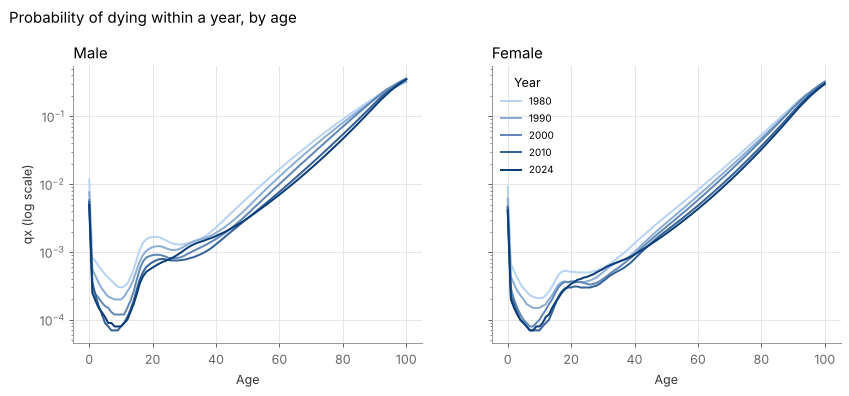

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
years_show = [1980, 1990, 2000, 2010, 2024]
blues = LinearSegmentedColormap.from_list("seq", ["#b7d3f5", "#0b3d78"])
for ax, s in zip(axes, ["male", "female"]):
    for i, y in enumerate(years_show):
        ax.plot(q[s].index[:101], q[s][y].iloc[:101], color=blues(i / (len(years_show) - 1)), lw=1.6, label=str(y))
    ax.set_yscale("log")
    ax.set_title(s.capitalize(), loc="left")
    ax.set_xlabel("Age")
axes[0].set_ylabel("qx (log scale)")
axes[1].legend(frameon=False, title="Year", fontsize=8)
fig.suptitle("Probability of dying within a year, by age", x=0.06, ha="left", y=1.04)
fig.savefig(f"{FIG_DIR}/qx_by_age.png", bbox_inches="tight", dpi=150)

## 4. Mortality improvement rates by age

The **annual improvement rate** at age *x* is how much `qx` falls each year: 1 − (q<sub>x,t</sub> / q<sub>x,t−1</sub>). Insurers and pension actuaries use improvement scales (for example the CIA's MI-2017) to project mortality into the future.

I smooth this by taking the average yearly change in log `qx` over a 10-year window, and leave out 2020–2022 so the pandemic doesn't distort the long-run picture.

In [6]:
def improvement(qm: pd.DataFrame, start: int, end: int) -> pd.Series:
    """Average annual improvement rate between two years (positive = falling mortality)."""
    return 1 - np.exp((np.log(qm[end]) - np.log(qm[start])) / (end - start))

periods = [(1980, 1990), (1990, 2000), (2000, 2010), (2009, 2019)]
bands = [(0, 0), (1, 19), (20, 39), (40, 59), (60, 79), (80, 89), (90, 100)]
rows = []
for s in ["male", "female"]:
    for a, b in bands:
        r = {"sex": s, "ages": f"{a}" if a == b else f"{a}–{b}"}
        for p0, p1 in periods:
            r[f"{p0}–{p1}"] = improvement(q[s].loc[a:b], p0, p1).mean() * 100
        rows.append(r)
imp = pd.DataFrame(rows).set_index(["sex", "ages"]).round(2)
imp

1980–1990  1990–2000  2000–2010  2009–2019
sex    ages                                              
male   0            4.26       2.62       0.66       0.34
       1–19         4.36       4.35       3.43       1.68
       20–39        1.50       2.79       1.62      -1.39
       40–59        2.84       2.21       1.71       0.98
       60–79        1.85       2.13       2.84       1.59
       80–89        0.92       0.68       2.16       1.19
       90–100       0.28      -0.77       0.83       0.40
female 0            3.99       2.67       0.35       1.99
       1–19         3.50       3.49       2.58       0.64
       20–39        2.34       1.25       1.22      -0.92
       40–59        2.38       1.27       1.42       1.42
       60–79        1.58       1.25       2.01       1.24
       80–89        0.93       0.47       1.70       0.87
       90–100       0.31      -0.42       0.94       0.42

**What stands out**
* From the 1980s to the 2000s, men aged 40–79 improved by about 2–3% a year, faster than women at the same ages. That is a big part of why the female–male life-expectancy gap shrank from 7.2 to about 4.3 years.
* In the decade before COVID (2009–2019), improvement **turned negative at ages 20–39** for both sexes (about −1.4%/yr for men, −0.9%/yr for women) and slowed at 40–59. The timing is consistent with the opioid overdose crisis, which mostly affects young and middle-aged adults.
* Ages 60+ kept improving, but more slowly than in the 2000s. One overall improvement rate hides these age differences, which is why the age-specific *b<sub>x</sub>* in Lee-Carter matters.

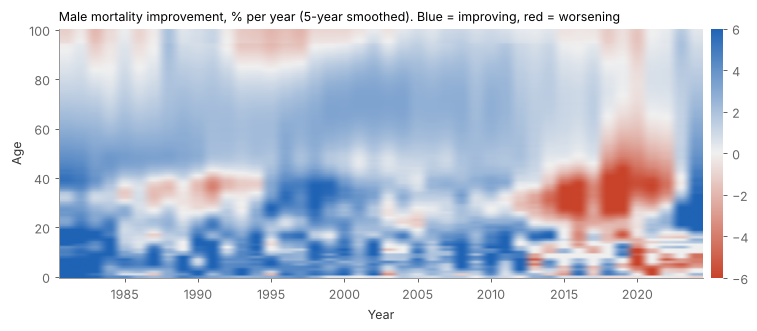

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
data = np.log(q["male"].loc[0:100]).diff(axis=1).iloc[:, 1:] * -100
data = data.T.rolling(5, center=True, min_periods=3).mean().T.clip(-6, 6)
div = LinearSegmentedColormap.from_list("div", ["#c8432a", "#f0f0f0", "#1f63b5"])
im = ax.imshow(data, aspect="auto", origin="lower", cmap=div, vmin=-6, vmax=6,
               extent=[data.columns[0] - 0.5, data.columns[-1] + 0.5, -0.5, 100.5])
ax.grid(False)
ax.set_xlabel("Year"); ax.set_ylabel("Age")
ax.set_title("Male mortality improvement, % per year (5-year smoothed). Blue = improving, red = worsening", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.outline.set_visible(False)
fig.savefig(f"{FIG_DIR}/improvement_heatmap_male.png", bbox_inches="tight", dpi=150)

The heat map shows the same story over time. Blue (improving) dominates middle and older ages from about 1995 to 2012. From around 2014 a red band (worsening) appears at ages ~15–55. In 2020–2022 the red spreads up to the oldest ages: that is the pandemic.

## 5. COVID-19: how big was the shock?

I compare actual 2020–2022 `qx` with what the 2009–2019 trend would have predicted at each age (a simple log-linear trend). The ratio actual ÷ expected is a rough **excess-mortality ratio**.

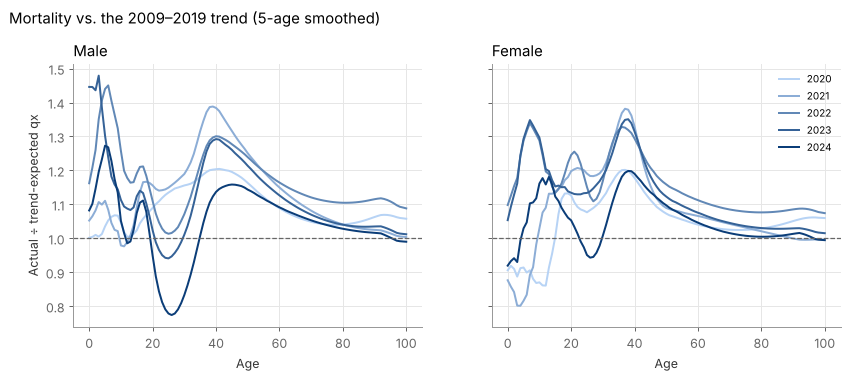

In [8]:
def trend_projection(qm: pd.DataFrame, fit_years: range, target: list[int]) -> pd.DataFrame:
    yrs = np.array(fit_years)
    logq = np.log(qm[list(yrs)].to_numpy())
    slope, intercept = np.polyfit(yrs, logq.T, 1)
    return pd.DataFrame(np.exp(intercept[:, None] + np.outer(slope, target)), index=qm.index, columns=target)

covid_years = [2020, 2021, 2022, 2023, 2024]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
excess = {}
for ax, s in zip(axes, ["male", "female"]):
    qm = q[s].loc[0:100]
    exp_q = trend_projection(qm, range(2009, 2020), covid_years)
    ratio = qm[covid_years] / exp_q
    excess[s] = ratio
    for i, y in enumerate(covid_years):
        r = ratio[y].rolling(5, center=True, min_periods=1).mean()
        ax.plot(r.index, r.values, color=blues(i / (len(covid_years) - 1)), lw=1.6, label=str(y))
    ax.axhline(1, color="#666666", lw=1, ls="--")
    ax.set_title(s.capitalize(), loc="left"); ax.set_xlabel("Age")
axes[0].set_ylabel("Actual ÷ trend-expected qx")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Mortality vs. the 2009–2019 trend (5-age smoothed)", x=0.06, ha="left", y=1.04)
fig.savefig(f"{FIG_DIR}/covid_excess_ratio.png", bbox_inches="tight", dpi=150)

In [9]:
bands2 = [(20, 44), (45, 64), (65, 84), (85, 100)]
tbl = pd.DataFrame({
    (s, f"{a}–{b}"): excess[s].loc[a:b].mean() for s in ["male", "female"] for a, b in bands2
}).T.round(3)
tbl

year            2020   2021   2022   2023   2024
male   20–44   1.163  1.252  1.152  1.106  0.949
       45–64   1.129  1.207  1.206  1.175  1.120
       65–84   1.046  1.064  1.115  1.057  1.042
       85–100  1.061  1.019  1.107  1.028  1.008
female 20–44   1.137  1.254  1.238  1.222  1.079
       45–64   1.061  1.084  1.140  1.105  1.076
       65–84   1.028  1.033  1.082  1.039  1.011
       85–100  1.054  0.999  1.082  1.025  1.007

**Takeaways for modelling**
* The biggest gap from trend is not at the oldest ages but around **ages 35–45**, up to about 40% above expected in 2021 for both sexes. Childhood ratios swing a lot because those rates are tiny (a few deaths per 100,000) and stored to 5 decimals.
* Relative to the pre-pandemic trend, ages 65–84 were about 5–12% above expected in 2020–2022 (worst in 2022), and young adults 20–44 were up to about 25% above expected in 2021.
* By 2024 the older ages are almost back on trend (ratios 1.01–1.04), but ages 45–64 are still about 8–12% above it, and women aged 20–44 about 8% above.
* So the 2015–2024 backtest window holds both the overdose-driven slowdown and the pandemic shock. Models shouldn't be judged on one overall number, so the next notebook also reports errors year by year.

**Next:** `02_lee_carter.ipynb`: fit Lee-Carter on 1980–2014, forecast 2015–2024, and compare it with a naive benchmark.